# Desempenho por dependência administrativa da escola

**Área de análise:** Pará (PA)  
**Referência territorial:** município da escola (ESC)  
**Período:** 1998–2025 para participação; 2001–2025 para desempenho.\
**Fonte:** `painel`,`grupo`

**OBJETIVO :**

A análise investiga as diferenças de participação e desempenho entre estudantes de escolas federais, estaduais, municipais e privadas. Os resultados permitem identificar desigualdades persistentes, mudanças na composição dos participantes e diferenças entre os municípios.

---
<div style="background-color: #f5f0dc; padding: 12px; border-radius: 6px;">
    
> **Nota Metodológica**\
>  As médias apresentadas são ponderadas pelo número de notas válidas. Já as medianas, quartis e medidas de dispersão são resumos de estatísticas municipais, não estatísticas calculadas diretamente sobre todos os participantes do Pará. Também é importante esclarecer a escala para valores anteriores a 2009.Eles aparecem em magnitudes compatíveis com a escala 0–1000, pois foram normalizados de forma linear.
 </div>
 
### Principais achados
<div style="background-color: #DBEAFE; padding: 12px; border-radius: 6px;">

> **Mudança na composição dos participantes**  
> A participação privada chegou a **24,7% em 2021**, mas recuou para **10,8% em 2025**, quando a rede pública voltou a representar **89,2%** dos participantes classificados.

> **Desigualdade de desempenho varia conforme a disciplina**  
> Em 2025, o gap público − privado foi de **−227,5 pontos em Redação** e **−117,2 pontos em Matemática**. Entre 2009 e 2025, as diferenças diminuíram em CH, CN e LC, mas aumentaram em Matemática e Redação.

> **Cobertura municipal elegível é limitada**  
> Em 2025, **61 de 710 combinações município-disciplina (8,59%)** atenderam ao critério de pelo menos 100 notas válidas em cada setor, restringindo a abrangência das comparações territoriais.

</div>

---

## Configuração e carga

In [10]:
from _setup2 import *

UF_PROCESSAMENTO = "PA"
TIPO_REFERENCIA = "ESC"

out = read_allfiles2(UF_PROCESSAMENTO, TIPO_REFERENCIA)

painel_esc = out["painel"]["data"].copy()
grupo = out["grupo"]["data"].copy()

desempenho_dep = eda2.preparar_desempenho_dependencia(grupo, referencia=TIPO_REFERENCIA)

print("=" * 46)
print(f"UF: {UF_PROCESSAMENTO}  | Período :{painel_esc ['ano'].min()}–{painel_esc ['ano'].max()}| Referência: {TIPO_REFERENCIA} ")
print("=" * 46)
print(f"painel  : {painel_esc .shape[0]:,} x {painel_esc .shape[1]}".replace(",", "."))
print(f"grupo   : {grupo.shape[0]:,} x {grupo.shape[1]}".replace(",", "."))
print("=" * 46)

UF: PA  | Período :1998–2025| Referência: ESC 
painel  : 3.625 x 82
grupo   : 186.449 x 16


## 1. Evolução da participação por dependência administrativa

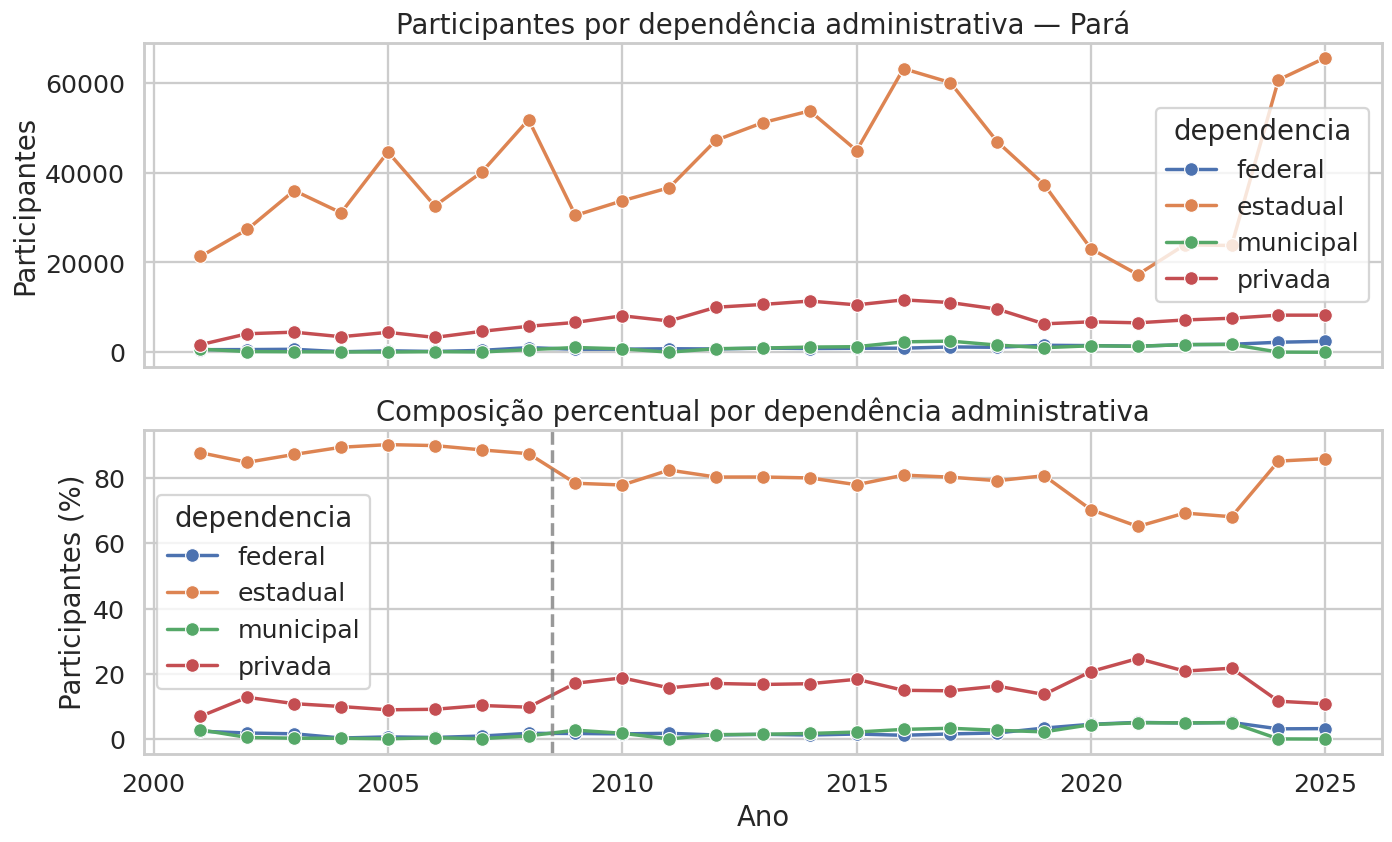

In [11]:
participacao_dep = eda2.calcular_participacao_dependencia(painel_esc)

participacao_dep["n_publica"] = (participacao_dep["federal"] + participacao_dep["estadual"] + participacao_dep["municipal"])
participacao_dep["n_privada"] = participacao_dep["privada"]
denominador_classificado = participacao_dep["n_dependencia_classificada"].where(participacao_dep["n_dependencia_classificada"].gt(0))

participacao_dep["pct_publica"] = (participacao_dep["n_publica"].div(denominador_classificado) * 100)
participacao_dep["pct_privada"] = (participacao_dep["n_privada"].div(denominador_classificado) * 100)

participacao_long = participacao_dep.melt(id_vars=["ano"],value_vars=["federal", "estadual", "municipal", "privada"],var_name="dependencia", value_name="participantes")
participacao_pct_long = participacao_dep.melt(
    id_vars=["ano"],
    value_vars=["pct_federal", "pct_estadual", "pct_municipal", "pct_privada"],
    var_name="dependencia", value_name="percentual")

participacao_pct_long["dependencia"] = participacao_pct_long["dependencia"].str.replace("pct_", "", regex=False)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
sns.lineplot(data=participacao_long, x="ano", y="participantes",hue="dependencia", marker="o", ax=axes[0])
axes[0].set(title="Participantes por dependência administrativa — Pará",xlabel="", ylabel="Participantes")

sns.lineplot(data=participacao_pct_long, x="ano", y="percentual",hue="dependencia", marker="o", ax=axes[1])
axes[1].set(title="Composição percentual por dependência administrativa",xlabel="Ano", ylabel="Participantes (%)")
axes[1].axvline(2008.5, color="gray", linestyle="--", alpha=.8)

plt.tight_layout()
plt.show()


### Comentários
A participação das escolas públicas foi predominante durante todo o período com informação disponível. Entretanto, a proporção de estudantes vinculados às escolas privadas aumentou entre o início dos anos 2000 e o final da década de 2010.

Em 2001, aproximadamente 93,0% dos participantes com dependência administrativa identificada eram provenientes de escolas públicas, enquanto 7,0% eram de escolas privadas. Em 2008, a participação pública era de 90,2%, e a privada alcançava 9,8%.

A partir de 2009, a participação privada aumentou. Em 2014, representava aproximadamente 17,0% dos participantes classificados. Em 2021, chegou a 24,7%, enquanto a participação pública recuou para 75,3%.

Nos anos seguintes, essa composição mudou novamente. Em 2025, as escolas públicas representavam 89,2% dos participantes classificados, contra 10,8% das escolas privadas.

| Ano  | Escolas públicas | Escolas privadas |
| ---- | ---------------- | ---------------- |
| 2001 | 93,0%            | 7,0%             |
| 2008 | 90,2%            | 9,8%             |
| 2009 | 82,9%            | 17,1%            |
| 2014 | 83,0%            | 17,0%            |
| 2019 | 86,3%            | 13,7%            |
| 2021 | 75,3%            | 24,7%            |
| 2023 | 78,3%            | 21,7%            |
| 2025 | 89,2%            | 10,8%            |

A participação das escolas privadas cresceu expressivamente até 2021, mas essa tendência não se manteve nos anos mais recentes. Em 2024 e 2025, a participação pública voltou a aumentar.

Um aspecto que merece atenção é a composição interna da rede pública. A rede estadual concentra a maior parte dos participantes. Em 2025, por exemplo, ela representava aproximadamente 85,9% dos participantes classificados.

Não existem informações sobre dependência administrativa entre 1998 e 2000. Esses anos não podem ser interpretados como ausência de participantes públicos ou privados.

Além disso, a forte redução da categoria municipal em 2024 e 2025 — chegando a apenas nove registros em 2025 — recomenda cautela na interpretação das mudanças recentes entre as categorias administrativas. É importante verificar se essa alteração decorre de mudanças na classificação ou na cobertura dos dados.



## 2. Diferença de desempenho entre escolas públicas e privadas

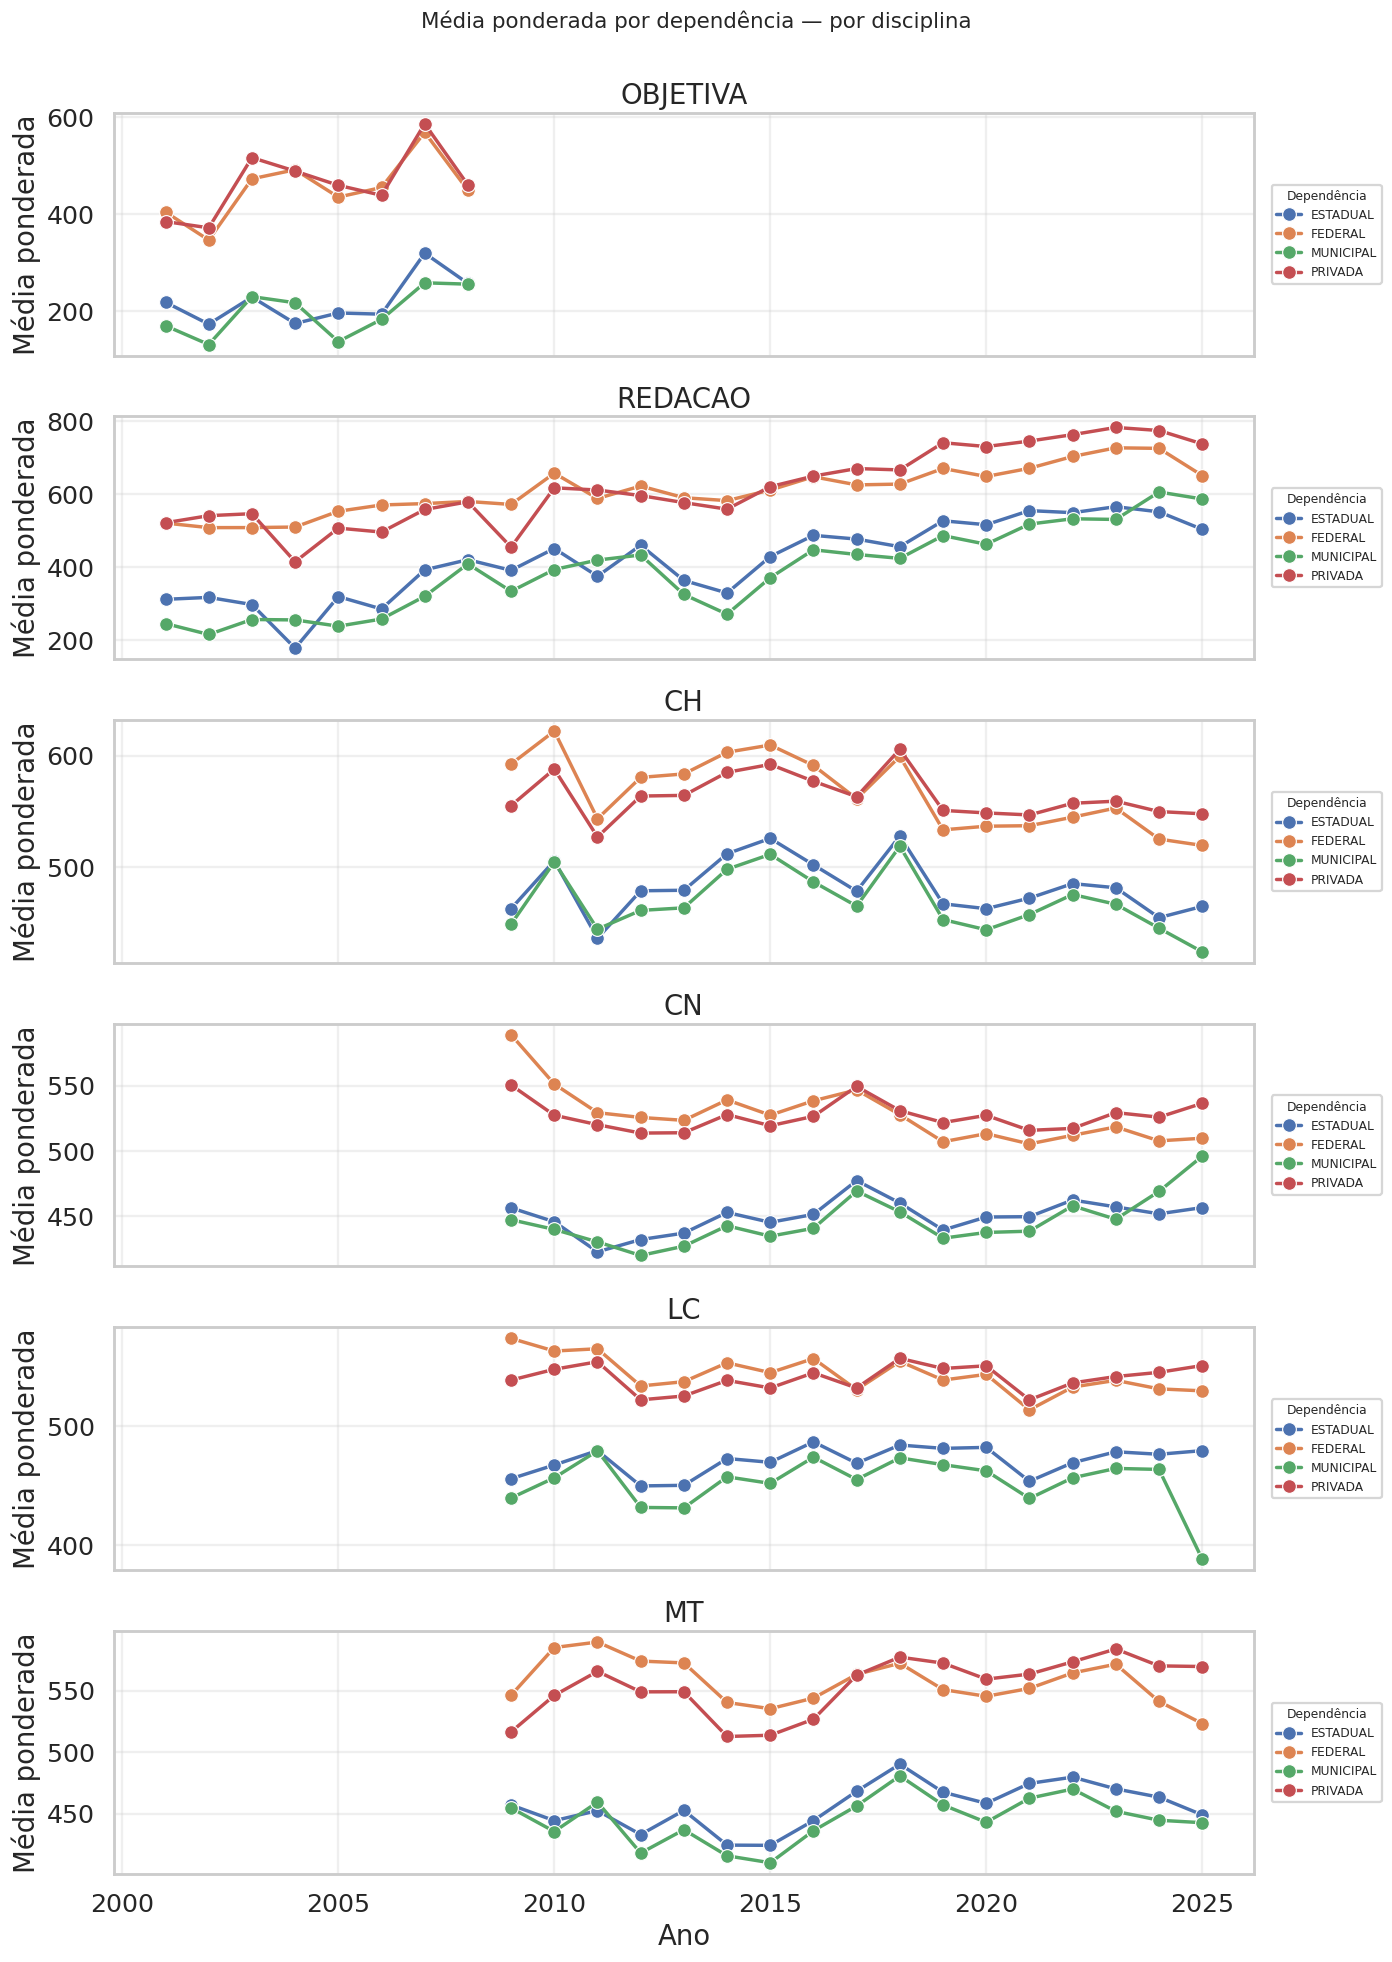

In [3]:
desempenho_categoria = eda2.agregar_desempenho_dependencia(
    desempenho_dep, por_municipio=False
)
desempenho_setor = eda2.calcular_gap_publica_privada(desempenho_categoria)

# Resumo de medianas municipais para comparação por setor e disciplina.
base_mediana = desempenho_dep.copy()
base_mediana["setor"] = np.where(
    base_mediana.dependencia.isin(["FEDERAL", "ESTADUAL", "MUNICIPAL"]),
    "PUBLICA",
    np.where(base_mediana.dependencia.eq("PRIVADA"), "PRIVADA", "NAO_INFORMADA")
)
base_mediana = base_mediana.loc[base_mediana.setor.isin(["PUBLICA", "PRIVADA"])]
medianas_setor = base_mediana.groupby(["ano", "disciplina", "setor"], as_index=False).agg(mediana_das_medianas_municipais=("mediana", "median"),
                                                                                          q1_das_medianas_municipais=("mediana", lambda s: s.quantile(.25)),
                                                                                          q3_das_medianas_municipais=("mediana", lambda s: s.quantile(.75)),
                                                                                          n_municipios=("CO_MUNICIPIO_TERRITORIO", "nunique"))


deps = ["FEDERAL", "ESTADUAL", "MUNICIPAL", "PRIVADA"]
disciplinas = ["OBJETIVA", "REDACAO", "CH", "CN", "LC", "MT"]

# ============================================================
# Figura 1 — Média ponderada por dependência
# ============================================================
fig, axes = plt.subplots(6, 1, figsize=(13,18), sharex=True)
for ax, disc in zip(axes, disciplinas):
    sub = desempenho_categoria.loc[
        desempenho_categoria.dependencia.isin(deps) &
        desempenho_categoria.disciplina.eq(disc)
    ]
    sns.lineplot(data=sub, x="ano", y="media_ponderada",
                 hue="dependencia", marker="o", ax=ax)
    ax.set(title=disc, ylabel="Média ponderada")
    ax.grid(alpha=0.3)
    ax.legend(title="Dependência", fontsize=8, title_fontsize=8,
              loc="center left", bbox_to_anchor=(1.01, 0.5))

axes[-1].set_xlabel("Ano")
fig.suptitle("Média ponderada por dependência — por disciplina",
             fontsize=14, y=0.995)
plt.tight_layout()
plt.show()


### Comentários:
Os resultados mostram uma vantagem persistente das escolas privadas em todas as disciplinas e nos períodos analisados.
A diferença é observada tanto nas médias ponderadas quanto nas medianas municipais. Entretanto, sua magnitude varia entre disciplinas e anos.No período de 2001 a 2008, a diferença entre as médias públicas e privadas foi particularmente elevada na prova objetiva e na Redação.

A partir de 2009, com a reorganização do exame, a comparação passa a considerar Ciências Humanas (CH), Ciências da Natureza (CN), Linguagens e Códigos (LC), Matemática (MT) e Redação. Entre 2009 e 2025, as diferenças médias observadas foram negativas em todas as disciplinas, indicando desempenho superior dos participantes das escolas privadas.

Alguns exemplos de 2025:

| Disciplina | Média privada | Média pública | Diferença pública − privada |
| ---------- | ------------- | ------------- | --------------------------- |
| CH         | 548,0         | 467,6         | -80,4                       |
| CN         | 531,0         | 453,7         | -77,3                       |
| LC         | 551,0         | 481,3         | -69,7                       |
| MT         | 569,9         | 452,7         | -117,2                      |
| Redação    | 755,5         | 528,0         | -227,5                      |

*Valores arredondados.*

A Redação apresenta a maior diferença entre os setores, seguida por Matemática. Linguagens e Códigos apresenta a menor diferença em 2025. As medianas municipais confirmam o padrão geral: as medianas das escolas privadas são, predominantemente, superiores às das escolas públicas.

A desigualdade de desempenho não está concentrada em uma única área do conhecimento. Ela aparece de maneira consistente nas diferentes disciplinas, embora sua intensidade varie. A Redação merece destaque pela distância mais elevada entre os setores.


## 3. Evolução do gap público–privado

O gap é definido como **média pública − média privada**. Valores negativos indicam média privada superior; valores positivos indicam média pública superior.

As notas estão padronizadas para a escala 0–1000. A comparação entre períodos anteriores e posteriores a 2009 deve considerar também a mudança de estrutura e de disciplinas do ENEM.


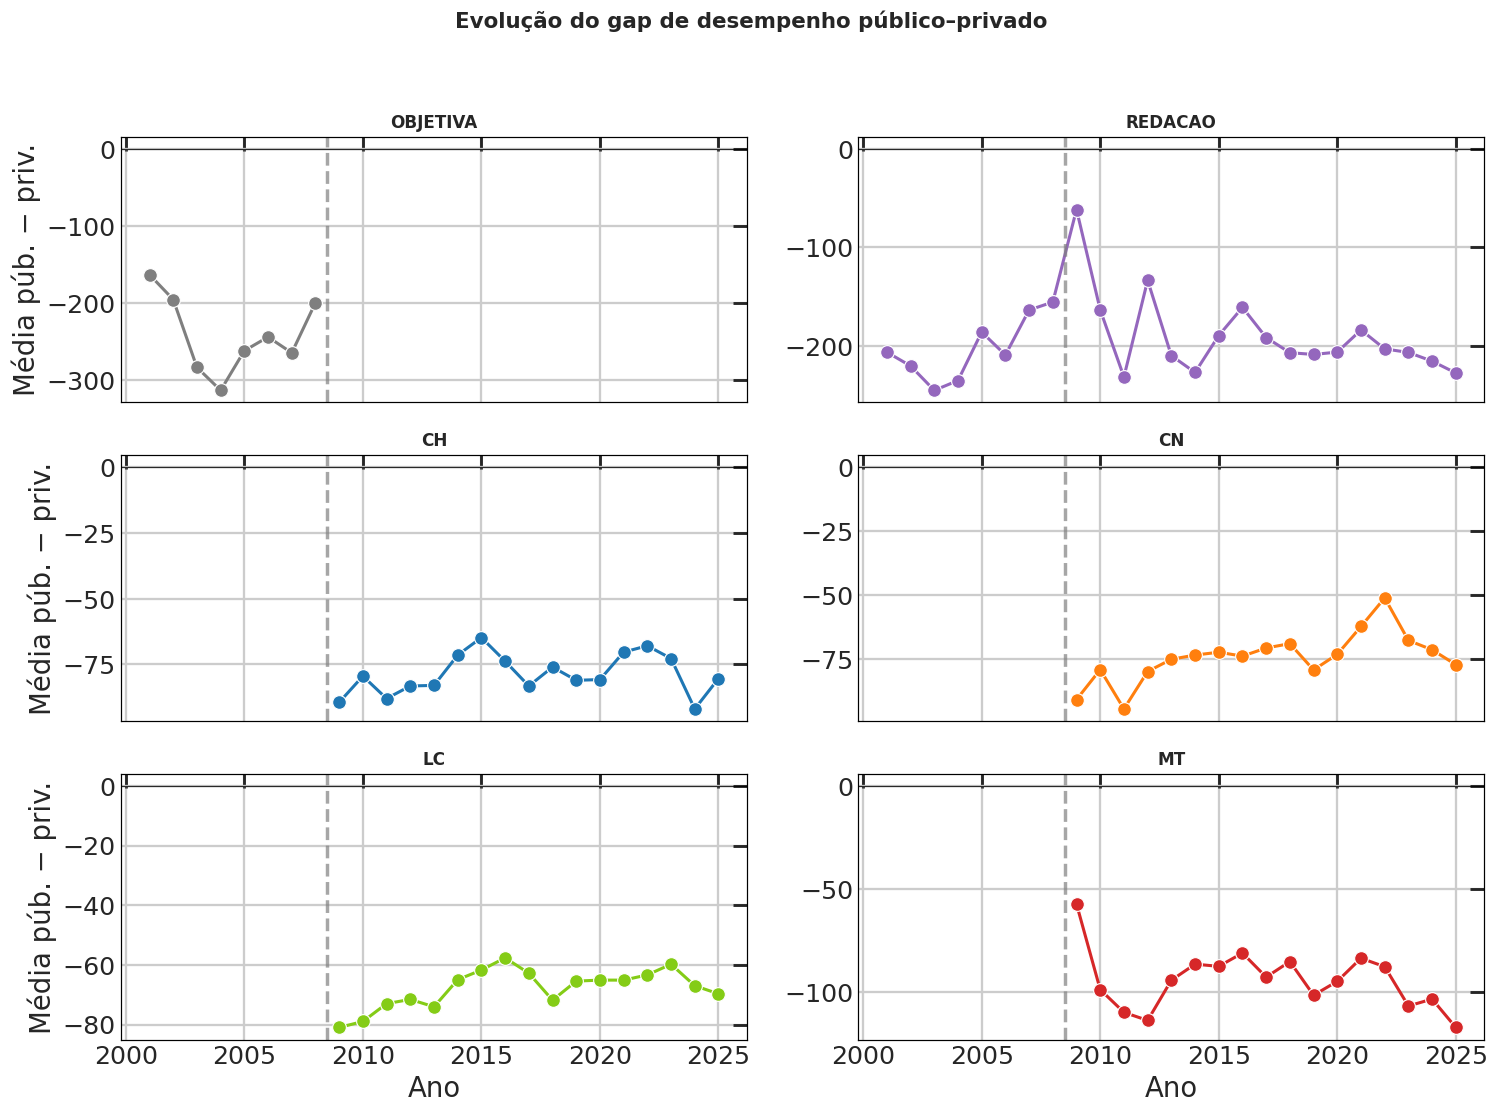

In [12]:
gap_temporal = desempenho_setor.copy()

# 1. Define as disciplinas na ordem desejada para o grid
disciplinas = ["OBJETIVA", "REDACAO", "CH", "CN", "LC", "MT"]

cores = {"CH": "#1f77b4", "CN": "#ff7f0e", "LC": "#84cc16", "MT": "#d62728", "REDACAO": "#9467bd", "OBJETIVA": "#7f7f7f"}


# 2. Cria a figura com subplots (3 linhas, 2 colunas)
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
axes = axes.ravel()

# 3. Loop pelos eixos e disciplinas
for ax, disc in zip(axes, disciplinas):
    # Filtra os dados da disciplina atual
    sub = gap_temporal.loc[gap_temporal.disciplina.eq(disc)]
    
    # Plota a linha
    sns.lineplot(
        data=sub, x="ano", y="gap_publica_menos_privada",
        marker="o", color=cores[disc], ax=ax, linewidth=2
    )
    
    # Configurações visuais do eixo
    ax.axhline(0, color="black", linewidth=.8, alpha=0.8)
    ax.axvline(2008.5, color="gray", linestyle="--", alpha=.7)
    ax.set_title(disc, fontsize=11, fontweight="bold")
    ax.set_ylabel("Média púb. − priv." if ax.get_subplotspec().is_first_col() else "")
    ax.set_xlabel("Ano" if ax.get_subplotspec().is_last_row() else "")
    
    # Fecha a caixa do plot (garante que as bordas apareçam)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(0.8)
    
    ax.tick_params(direction='in', top=True, right=True)

# 4. Título geral
fig.suptitle("Evolução do gap de desempenho público–privado", 
             fontsize=14, fontweight="bold", y=1.02)

# 5. Ajuste de layout
plt.tight_layout()
plt.show()

### Comentários:
A análise das diferenças anuais mostra que não houve uma trajetória uniforme de redução ou ampliação da desigualdade.
Entre 2009 e 2025, observam-se comportamentos distintos conforme a disciplina. Diferença calculada como média pública ponderada menos média privada ponderada. Valores negativos indicam vantagem privada.

| Disciplina | Diferença em 2009 | Diferença em 2025 | Comportamento        |
| ---------- | ----------------- | ----------------- | -------------------- |
| CH         | -89,4             | -80,4             | Redução moderada     |
| CN         | -91,0             | -77,3             | Redução              |
| LC         | -80,9             | -69,7             | Redução              |
| MT         | -57,3             | -117,2            | Ampliação            |
| Redação    | -61,6             | -227,5            | Ampliação expressiva |

A diferença em Ciências Humanas, Ciências da Natureza e Linguagens diminuiu ao longo do período, embora permaneça favorável às escolas privadas.

Em Matemática, ocorreu o movimento contrário: a diferença aumentou, passando de aproximadamente 57 pontos em 2009 para 117 pontos em 2025. Na Redação, a diferença também aumentou de maneira expressiva. É importante observar que 2009 apresenta uma diferença inicial relativamente pequena, seguida de ampliação nos anos posteriores.

Não é adequado afirmar que a desigualdade entre escolas públicas e privadas aumentou ou diminuiu de maneira geral. O comportamento depende da disciplina. Os resultados sugerem uma redução relativa das diferenças em CH, CN e LC, mas uma ampliação em Matemática e Redação. Portanto, as desigualdades de desempenho apresentam componentes específicos de cada área do conhecimento.



## 4. Desempenho nas quatro categorias administrativas

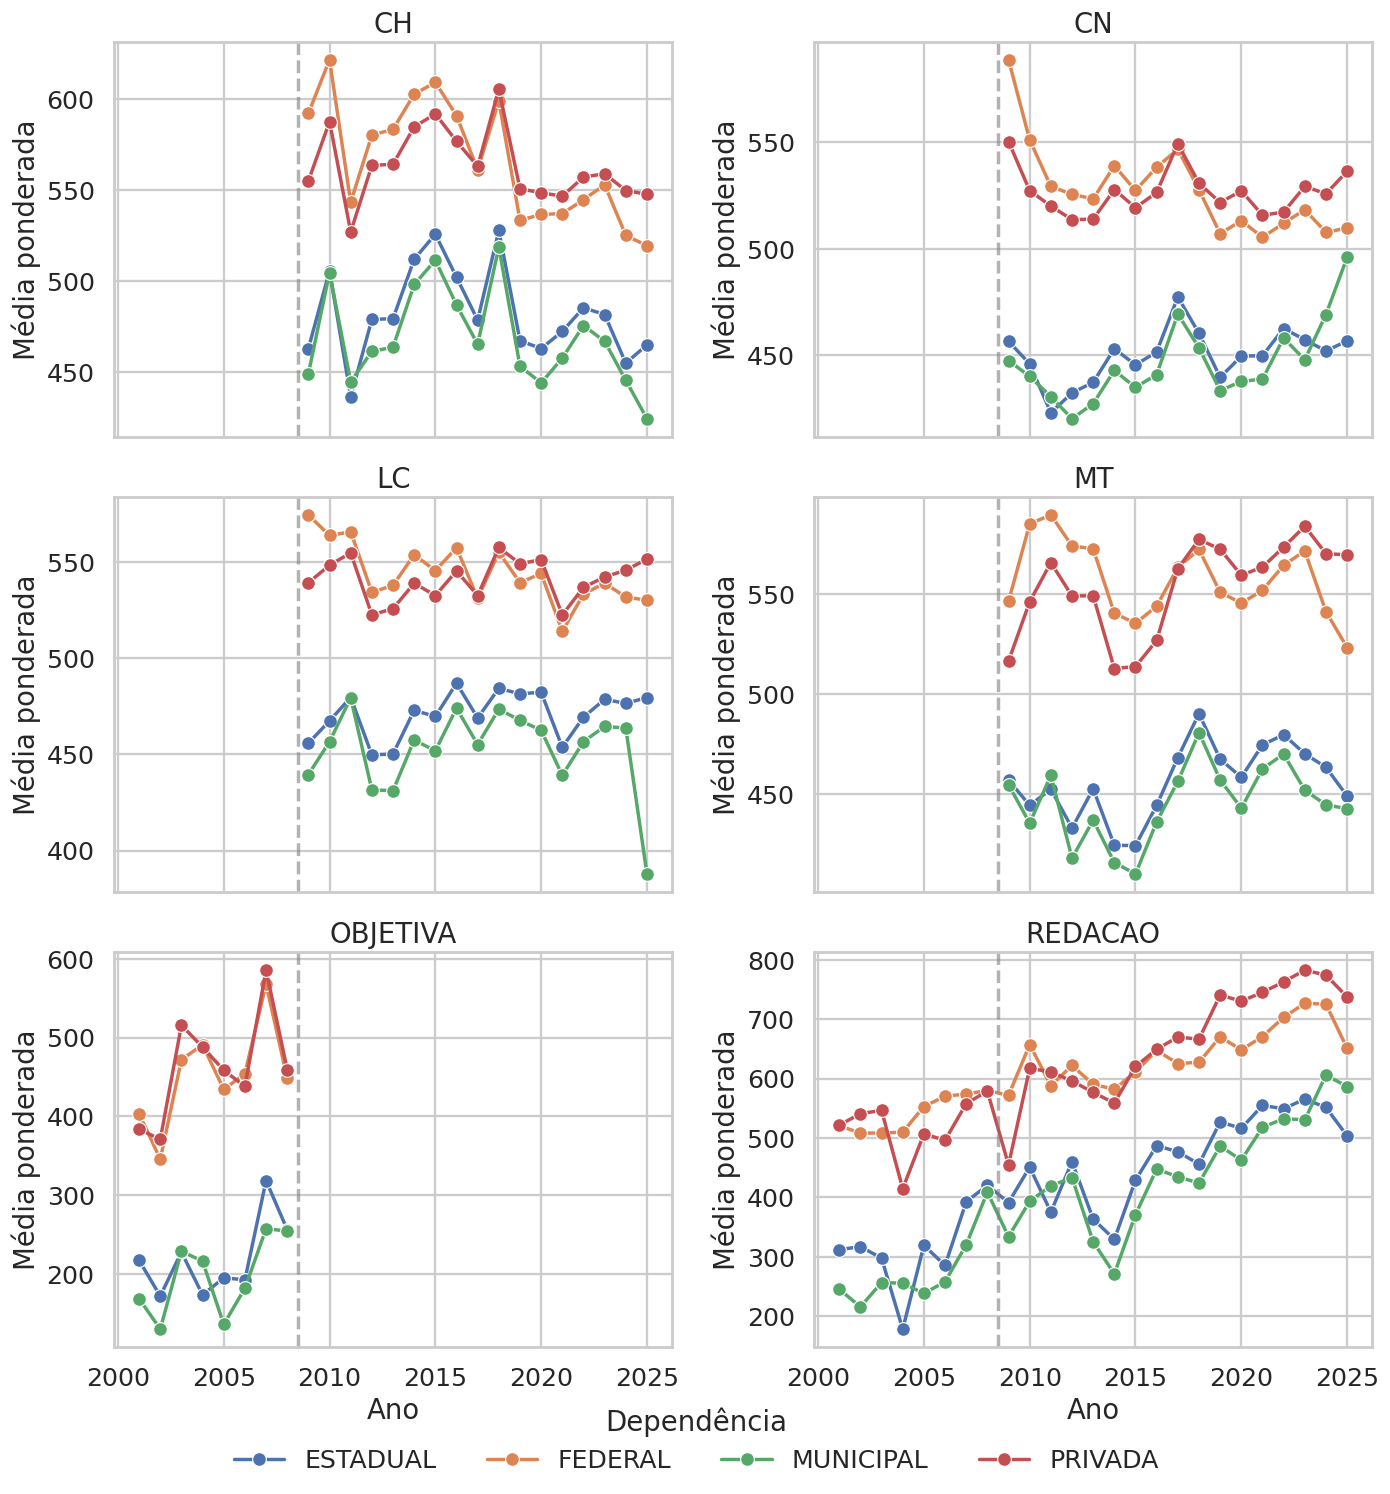

In [5]:
desempenho_quatro = desempenho_categoria.copy()

disciplinas_e04 = sorted(desempenho_quatro.disciplina.dropna().unique())
ncols = 2
nrows = int(np.ceil(len(disciplinas_e04) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4.5 * nrows), sharex=True)
axes = np.atleast_1d(axes).ravel()

# Variável para armazenar os handles e labels da legenda
handles, labels = None, None

for ax, disc in zip(axes, disciplinas_e04):
    tmp = desempenho_quatro.loc[
        desempenho_quatro.disciplina.eq(disc)
        & desempenho_quatro.dependencia.isin(["FEDERAL", "ESTADUAL", "MUNICIPAL", "PRIVADA"])
    ]
    sns.lineplot(data=tmp, x="ano", y="media_ponderada",
                 hue="dependencia", marker="o", ax=ax)
    
    ax.axvline(2008.5, color="gray", linestyle="--", alpha=.6)
    ax.set(title=disc, xlabel="Ano", ylabel="Média ponderada")
    
    # Remove a legenda individual do subplot
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    
    # Captura os handles e labels apenas do primeiro eixo
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

# Esconde eixos sobrando (se houver)
for ax in axes[len(disciplinas_e04):]:
    ax.set_visible(False)

# Cria a legenda única na parte inferior da figura
fig.legend(handles, labels, 
           loc="lower center", 
           ncol=4, # Deixa os itens em uma única linha horizontal
           bbox_to_anchor=(0.5, -0.02), # Ajusta a posição vertical (para baixo)
           title="Dependência", 
           frameon=False)

# Ajusta o layout e adiciona espaço embaixo para a legenda não cortar
plt.tight_layout()
plt.subplots_adjust(bottom=0.08) # Aumenta o espaço inferior se necessário
plt.show()


### Comentários:
A comparação das quatro dependências administrativas revela uma hierarquia relativamente consistente.
De modo geral:

1. Escolas federais apresentam médias elevadas, frequentemente próximas ou superiores às escolas privadas.

2. Escolas privadas apresentam desempenho superior às escolas estaduais e municipais.

3. Escolas estaduais concentram grande parte dos participantes e apresentam resultados intermediários.

4. Escolas municipais apresentam, em geral, médias inferiores às estaduais.

Essa organização aparece nas quatro áreas do conhecimento após 2009.

Considerando as médias dos anos de 2009 a 2019, temos:

| Disciplina | Federal | Privada | Estadual | Municipal |
| ---------- | ------- | ------- | -------- | --------- |
| CH         | 583,6   | 570,2   | 489,0    | 478,1     |
| CN         | 536,8   | 527,3   | 447,4    | 440,0     |
| LC         | 550,7   | 540,6   | 469,7    | 456,2     |
| MT         | 561,1   | 544,6   | 450,7    | 441,8     |
| Redação    | 617,6   | 614,7   | 431,5    | 394,5     |


As escolas federais apresentam os maiores resultados médios em todas as disciplinas nesse recorte. A diferença entre escolas federais e privadas, entretanto, é relativamente pequena. As escolas estaduais e municipais apresentam resultados inferiores. A distância é particularmente expressiva na Redação. Os resultados sugerem que a dependência administrativa está associada a diferenças importantes de desempenho. Entretanto, não se deve interpretar essa hierarquia como efeito causal da dependência administrativa. A composição socioeconômica, a seleção dos participantes, a localização das escolas e outros fatores não foram isolados nesta análise.

Também é importante considerar que o número de municípios representados varia entre as categorias. As escolas federais, por exemplo, possuem cobertura territorial menor, de modo que seus resultados não devem ser generalizados automaticamente para todos os municípios.



## 5. Participação pública e desempenho médio

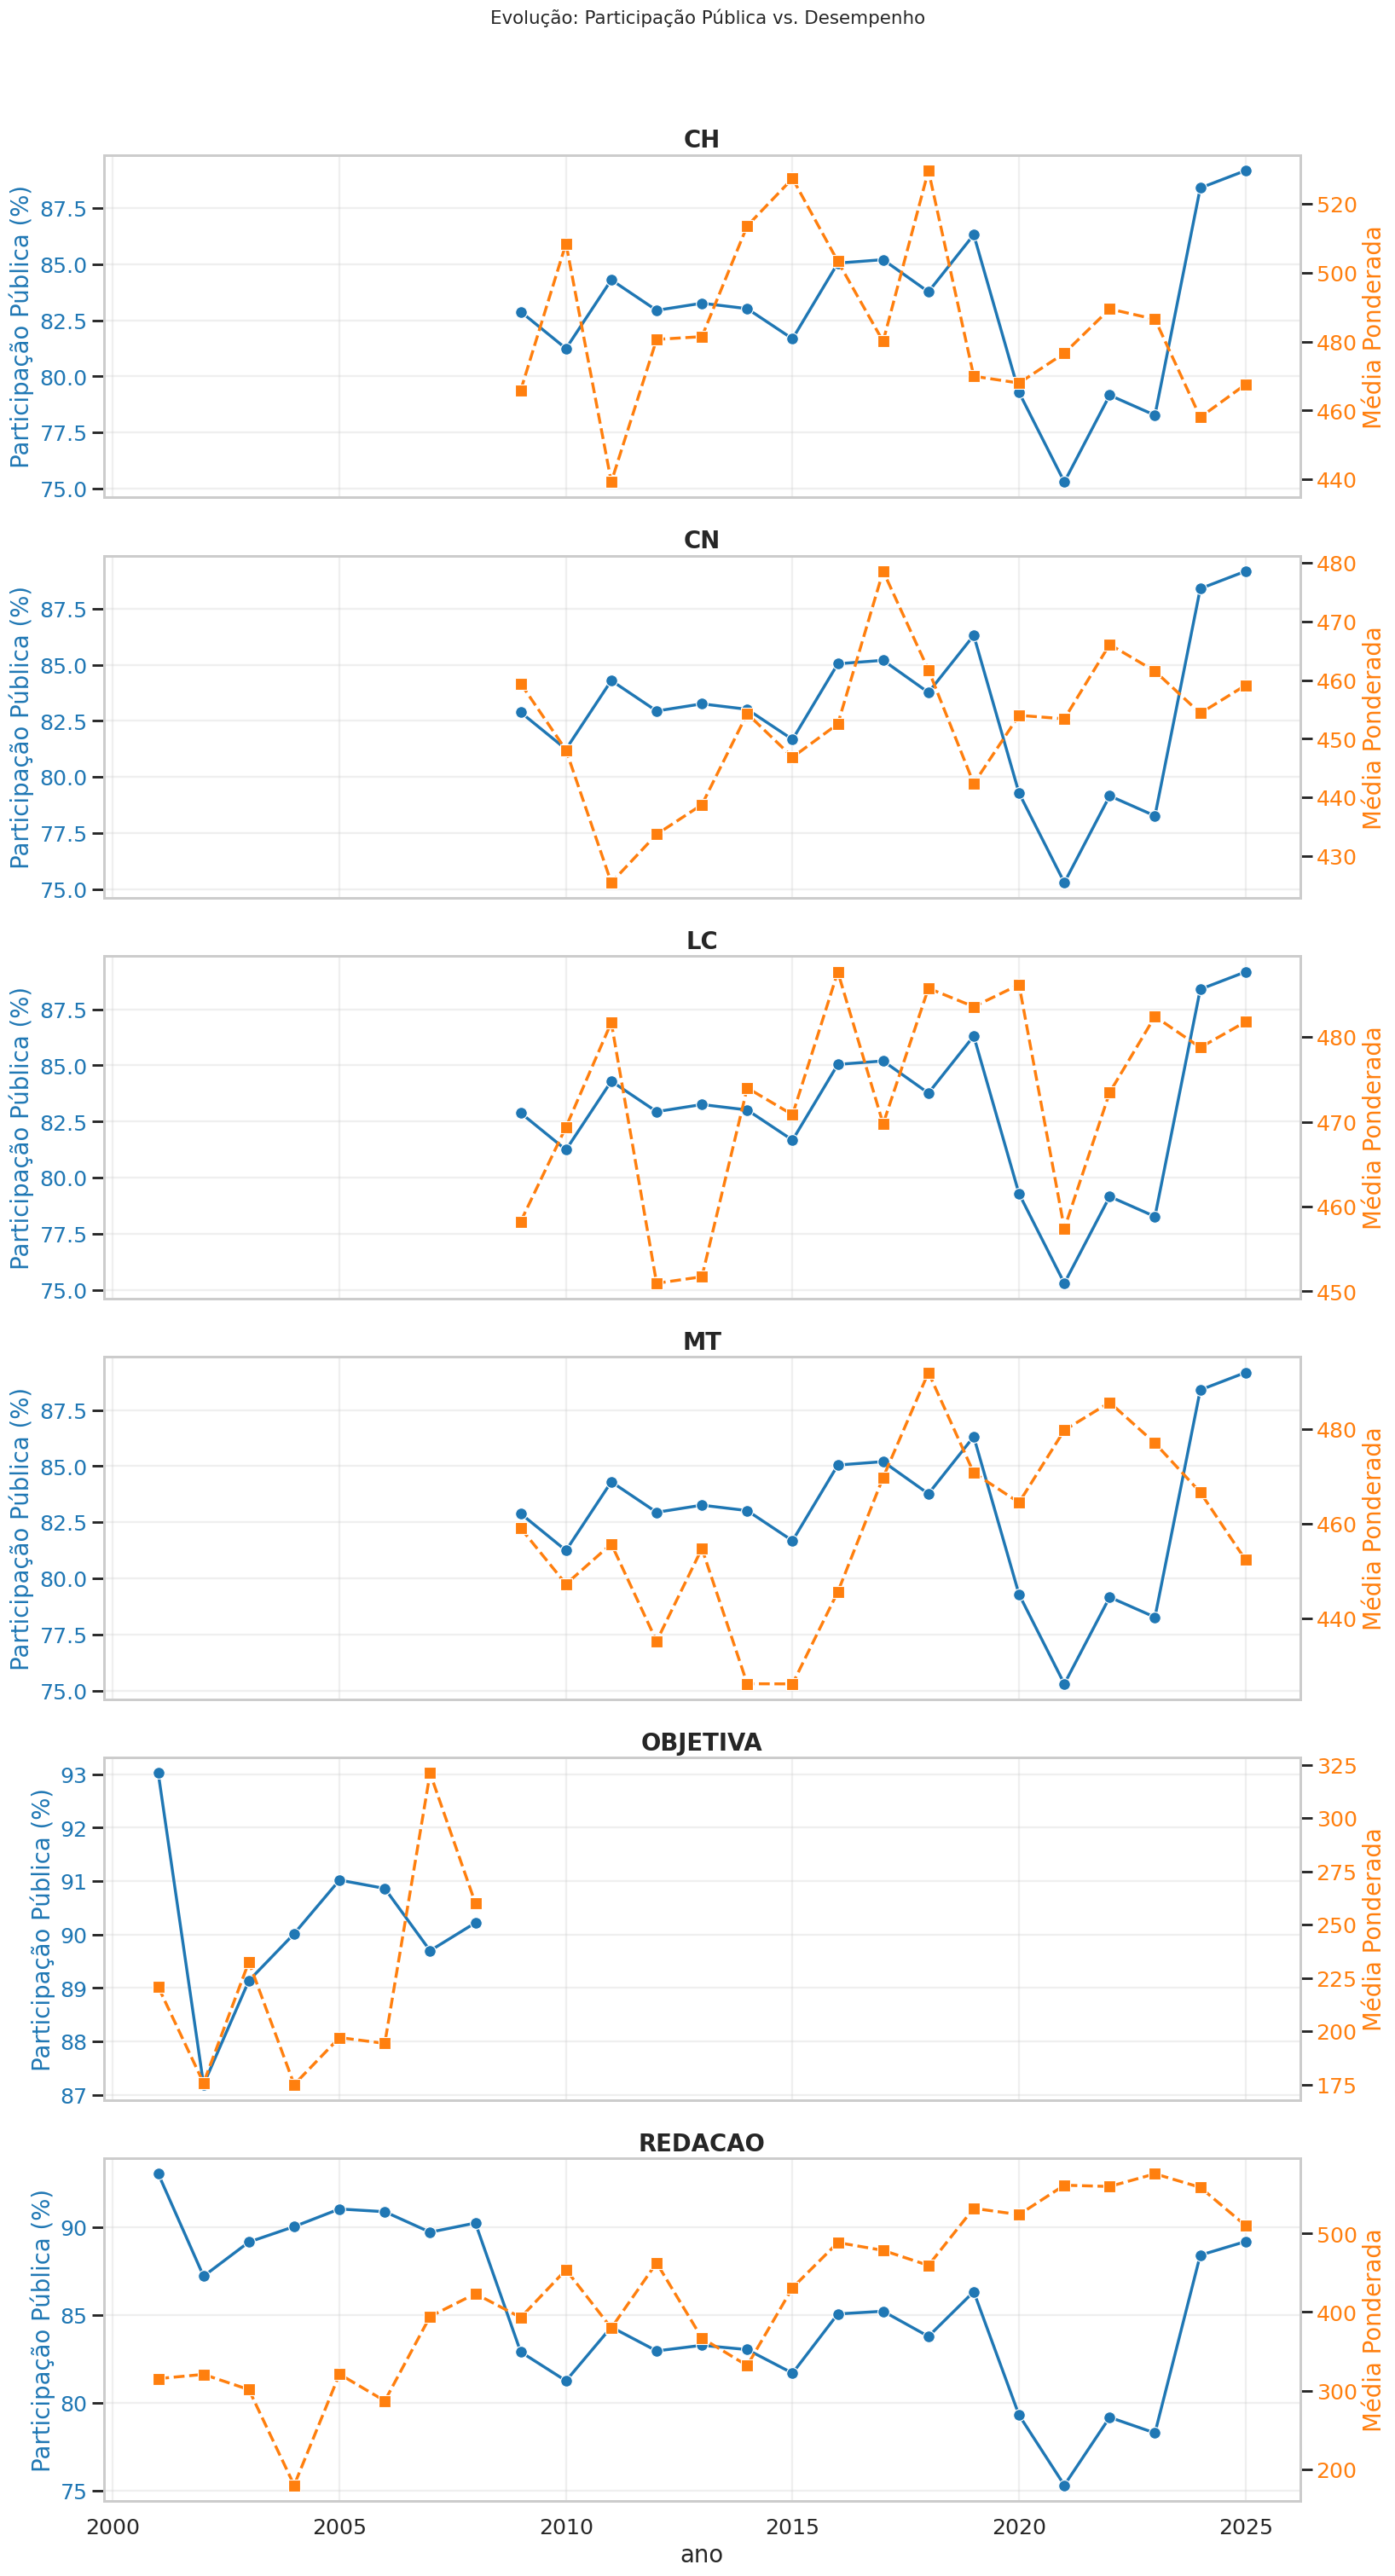

In [6]:
participacao_publica = participacao_dep[["ano", "n_publica", "n_privada", "n_dependencia_classificada", "pct_publica", "pct_privada"]].copy()

desempenho_publico = desempenho_dep.loc[desempenho_dep.dependencia.isin(["FEDERAL", "ESTADUAL", "MUNICIPAL"])].copy()
desempenho_publico["_soma"] = desempenho_publico.media * desempenho_publico.n_validos
desempenho_publico_anual = desempenho_publico.groupby(["ano", "disciplina"], as_index=False
).agg(soma_ponderada=("_soma", "sum"),n_validos=("n_validos", "sum"))
desempenho_publico_anual["media_publica_ponderada"] = (desempenho_publico_anual.soma_ponderada / desempenho_publico_anual.n_validos)

participacao_desempenho = participacao_publica.merge(desempenho_publico_anual, on="ano", how="inner")
#display(participacao_desempenho)

disciplinas = sorted(participacao_desempenho.disciplina.dropna().unique())
ncols = 1
nrows = int(np.ceil(len(disciplinas) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows), sharex=True)
axes = np.atleast_1d(axes).ravel()

for ax, disc in zip(axes, disciplinas):
    sub = participacao_desempenho.loc[participacao_desempenho.disciplina.eq(disc)].sort_values("ano")
    
    # Eixo 1: Participação (Linha)
    sns.lineplot(data=sub, x="ano", y="pct_publica", marker="o", color="tab:blue", ax=ax)
    ax.set_ylabel("Participação Pública (%)", color="tab:blue")
    ax.tick_params(axis='y', labelcolor="tab:blue")
    
    # Eixo 2: Desempenho (Linha tracejada)
    ax2 = ax.twinx()
    sns.lineplot(data=sub, x="ano", y="media_publica_ponderada", marker="s", color="tab:orange", linestyle="--", ax=ax2)
    ax2.set_ylabel("Média Ponderada", color="tab:orange")
    ax2.tick_params(axis='y', labelcolor="tab:orange")
    
    ax.set_title(disc, fontweight="bold")
    ax.grid(alpha=0.3)
    
    # Remove o grid do eixo secundário para não poluir
    ax2.grid(False)

for ax in axes[len(disciplinas):]:
    ax.set_visible(False)

fig.suptitle("Evolução: Participação Pública vs. Desempenho", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


### Comentários

Os resultados não indicam uma relação direta e uniforme entre a participação pública
e o desempenho médio.A participação pública permaneceu majoritária, mas apresentou variações 
expressivas. Entre 2009 e 2021, por exemplo, sua participação passou de aproximadamente 82,9% para 75,3%.
Entretanto, o desempenho médio público não acompanhou esse movimento de maneira uniforme.

Entre 2009 e 2025:

- CH passou de 465,8 ➜ 467,6 pontos.
- CN passou de 459,4 ➜ 459,1 pontos.
- LC passou de 458,2 ➜ 481,8 pontos.
- MT passou de 459,1 ➜ 452,3 pontos.

Esses resultados mostram que algumas disciplinas apresentaram estabilidade, outras evolução positiva e outras redução.Na Redação, a série apresenta um comportamento diferente: a média pública aumentou em relação ao início da série, embora também tenha apresentado oscilações.

O aumento ou a redução da participação pública não foi acompanhado por uma mudança proporcional e homogênea no desempenho médio. A participação representa a composição dos participantes do exame, enquanto o desempenho representa o resultado acadêmico desse grupo. As duas dimensões estão relacionadas ao contexto educacional, mas não podem ser interpretadas como uma relação causal direta. Portanto, a expansão da participação das escolas públicas, isoladamente, não explica as mudanças observadas nas médias.


## 6. Diferenças territoriais no gap público–privado

A análise histórica de desigualdade territorial não será tratada como respondida: com o critério mínimo de 30 notas válidas em cada setor, a base disponível só permite comparação elegível em 2025.


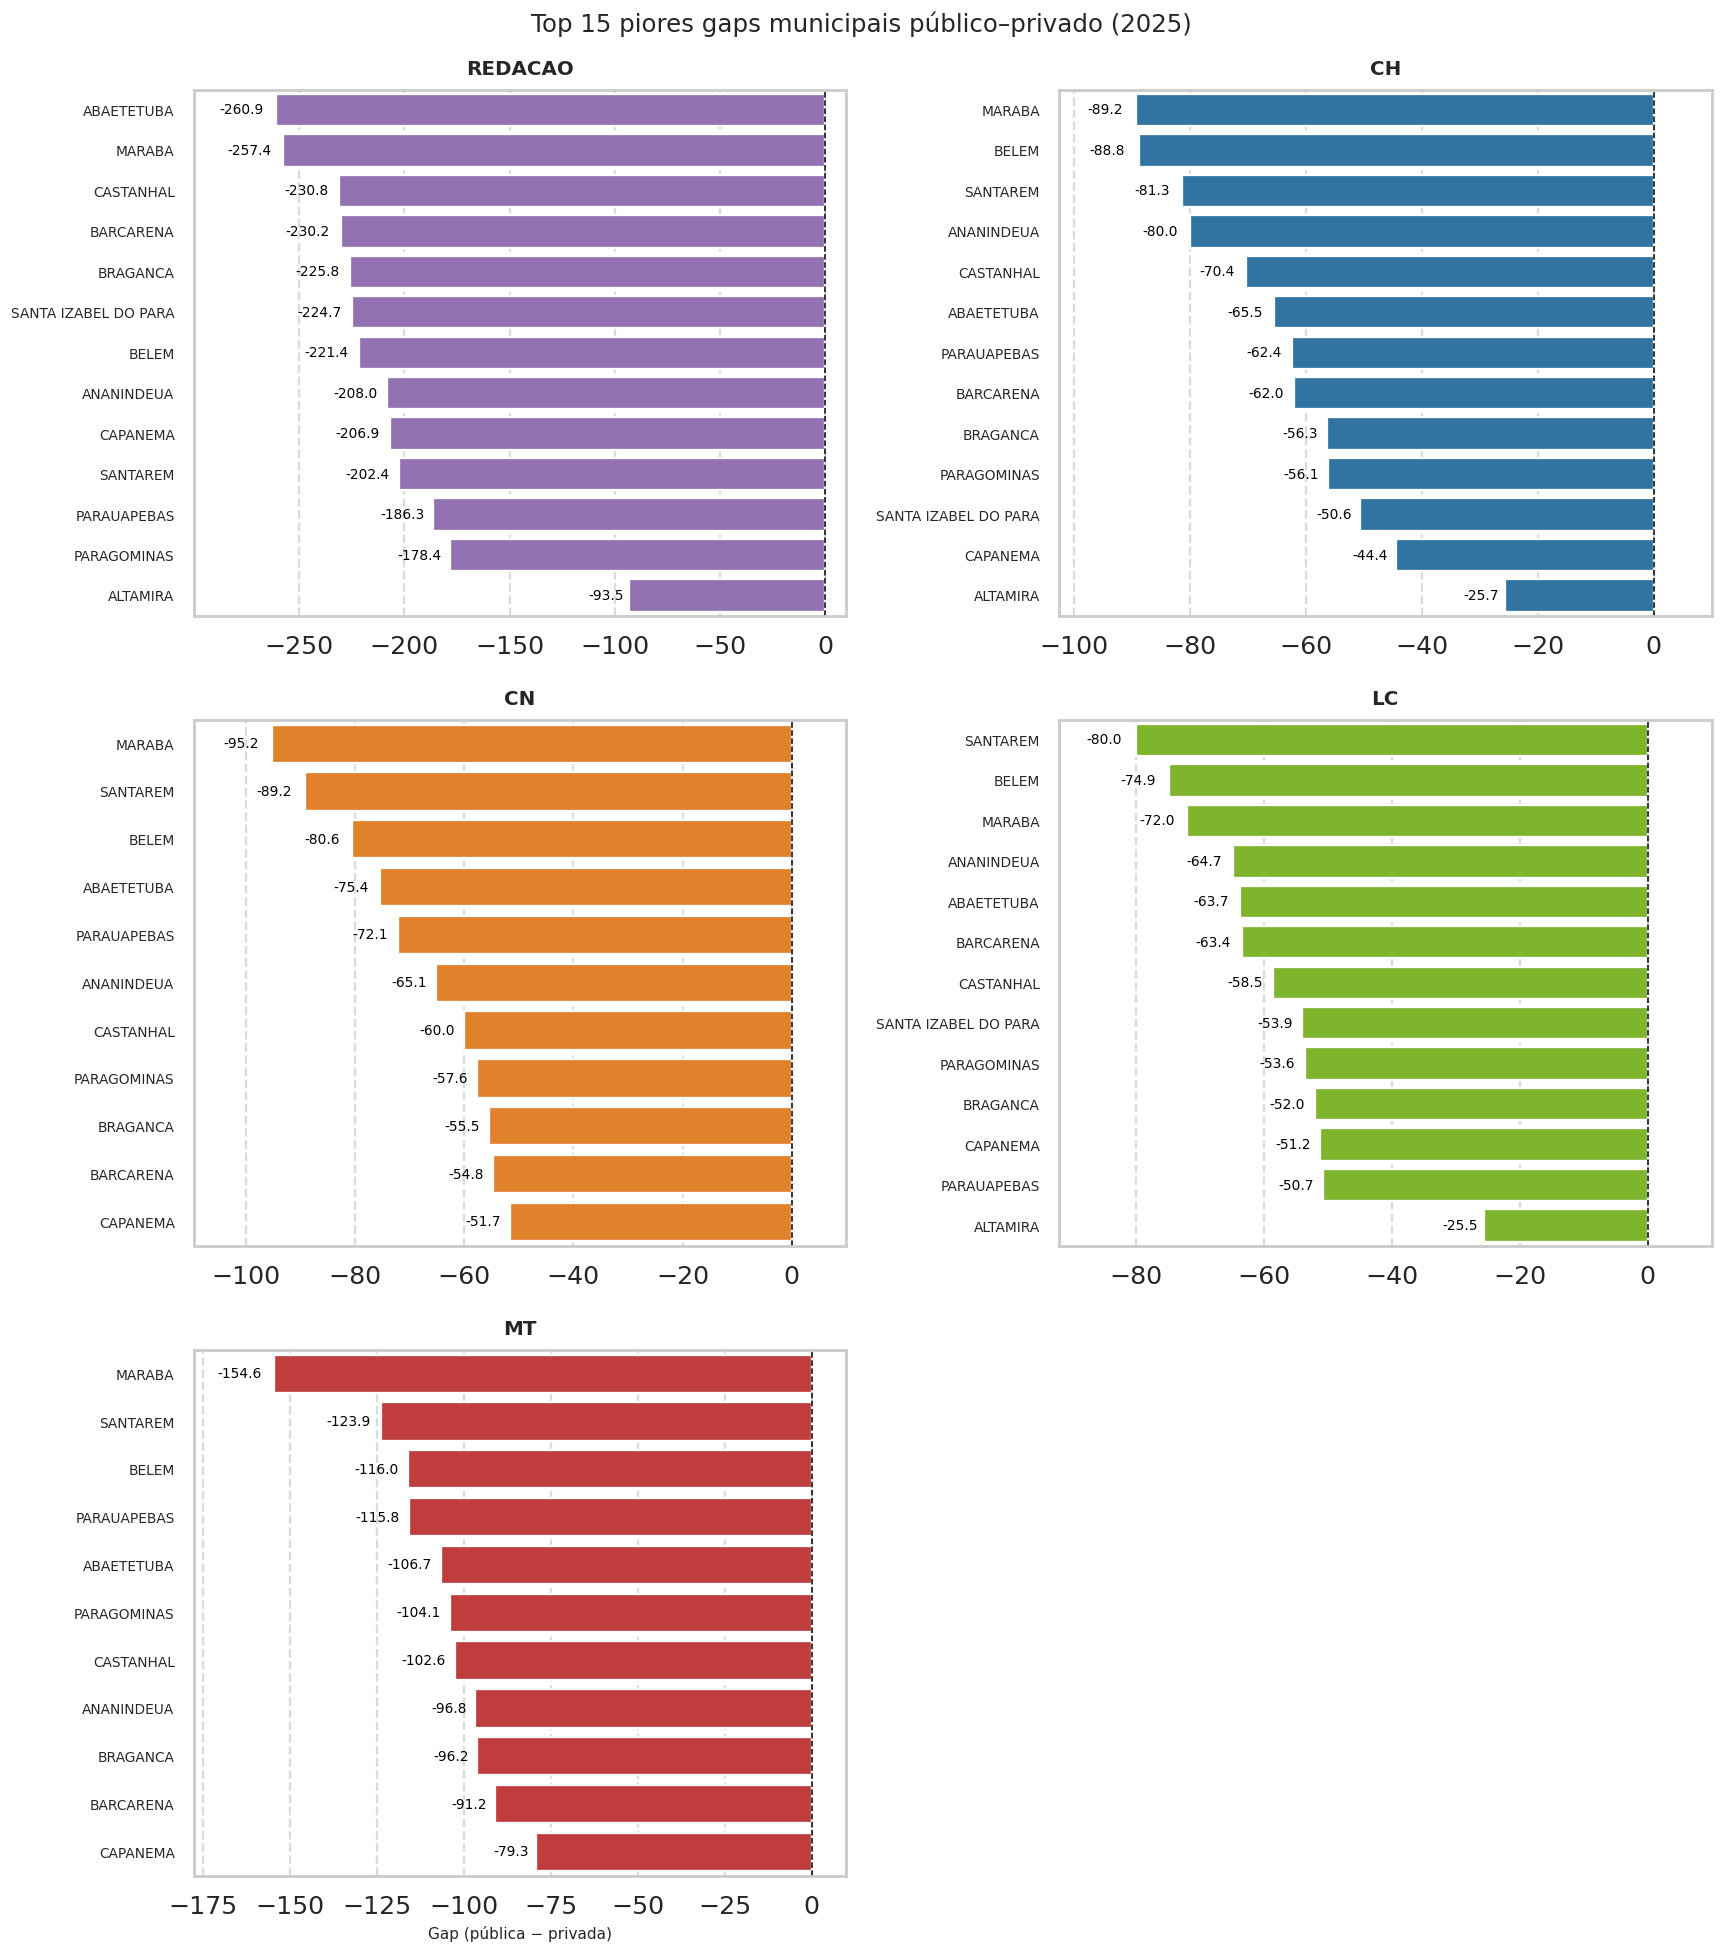

In [14]:
N_MINIMO_VALIDOS_SETOR = 100

desempenho_municipal = eda2.agregar_desempenho_dependencia(desempenho_dep, por_municipio=True)
gap_municipal = eda2.calcular_gap_publica_privada(desempenho_municipal, por_municipio=True)

gap_municipal["elegivel"] = (gap_municipal["n_validos_publica"].ge(N_MINIMO_VALIDOS_SETOR)& gap_municipal["n_validos_privada"].ge(N_MINIMO_VALIDOS_SETOR))
ANO_MUNICIPAL = int(gap_municipal.ano.max())
gap_municipal_final = gap_municipal.loc[gap_municipal.ano.eq(ANO_MUNICIPAL) & gap_municipal.elegivel].copy()

cobertura_elegibilidade_e06 = gap_municipal.groupby("ano", as_index=False).agg(combinacoes_municipio_disciplina=("disciplina", "size"),combinacoes_elegiveis=("elegivel", "sum"),)
cobertura_elegibilidade_e06["percentual_elegivel"] = (cobertura_elegibilidade_e06["combinacoes_elegiveis"]/ cobertura_elegibilidade_e06["combinacoes_municipio_disciplina"] * 100)


pd.set_option('display.max_rows', None)
# display(gap_municipal_final.sort_values(
#     "gap_publica_menos_privada", ascending=False
# ))
N_MINIMO_VALIDOS_SETOR = 100
TOP_N = 15 
disciplinas_alvo = [ "REDACAO", "CH", "CN", "LC", "MT"]

# 1. Configuração da grade
fig, axes = plt.subplots(3, 2, figsize=(16, 18), sharex=False)
axes = axes.ravel()

# 2. Loop pelas disciplinas
for ax, disciplina in zip(axes, disciplinas_alvo):
    # Filtra os dados
    plot_municipal = gap_municipal_final.loc[
        gap_municipal_final.disciplina.eq(disciplina)
    ].copy()
    
    # Se não houver dados, desliga o eixo
    if plot_municipal.empty:
        ax.set_visible(False)
        continue
        
    # Top N com os piores gaps
    plot_top = plot_municipal.nsmallest(TOP_N, "gap_publica_menos_privada")
    
    # Plota as barras
    sns.barplot(
        data=plot_top, 
        x="gap_publica_menos_privada",
        y="NO_MUNICIPIO_TERRITORIO", 
        color=cores[disciplina], 
        ax=ax
    )
    
    # Linha do zero e grid
    ax.axvline(0, color="black", linewidth=1, linestyle="--")
    ax.grid(axis='x', linestyle='--', alpha=0.7)
    
    # Anotações de valor
    for i, (_, row) in enumerate(plot_top.iterrows()):
        valor = row["gap_publica_menos_privada"]
        offset = (abs(valor) * 0.02) + 0.5 # offset dinâmico para não encostar na barra
        
        ax.text(
            valor - offset, 
            i, 
            f"{valor:.1f}", 
            va="center", 
            ha="right", 
            fontsize=9, 
            color="black",
        )
    
    # Títulos e rótulos
    ax.set_title(f"{disciplina}", fontsize=13, fontweight="bold", pad=10)
    ax.set_xlabel("Gap (pública − privada)" if ax in axes[4:] else "", fontsize=10)
    ax.set_ylabel("") # Remove "Município" repetido para economizar espaço
    
    # Ajuste do eixo X para respiro
    min_val = plot_top["gap_publica_menos_privada"].min()
    limite_esq = min_val - (abs(min_val) * 0.15) if min_val < 0 else min_val - 10
    ax.set_xlim(limite_esq, 10)
    
    # Ajusta o tamanho da fonte dos nomes dos municípios no eixo Y
    ax.tick_params(axis='y', labelsize=9)

# 3. Esconde eixos excedentes (caso não haja exatamente 6 disciplinas)
for ax in axes[len(disciplinas_alvo):]:
    ax.set_visible(False)

# 4. Título geral e layout
fig.suptitle(f"Top {TOP_N} piores gaps municipais público–privado ({ANO_MUNICIPAL})", 
             fontsize=16, y=0.99)
plt.tight_layout()
plt.subplots_adjust(top=0.95) # Dá espaço para o suptitle
plt.show()



### Comentários

A comparação territorial permite investigar as diferenças entre as médias das escolas públicas e privadas nos municípios paraenses. Para essa análise, foram consideradas elegíveis as combinações município-disciplina que apresentaram, no mínimo, 100 notas válidas em cada setor.

A cobertura de elegibilidade varia ao longo da série histórica. Entre 2001 e 2025, foram identificadas combinações elegíveis em todos os anos, mas sua proporção em relação ao total de combinações município-disciplina disponíveis permaneceu limitada. O percentual variou de 1,46%, em 2004, a 13,29%, em 2016. Em 2025, foram identificadas 61 combinações elegíveis entre 710, correspondendo a 8,59%.

| Disciplina | Combinações elegíveis | Diferença mediana municipal |
| ---------- | --------------------- | --------------------------- |
| CH         | 13                    | −62,4                       |
| CN         | 11                    | −65,1                       |
| LC         | 13                    | −58,5                       |
| MT         | 11                    | −104,1                      |
| Redação    | 13                    | −221,4                      |
| **Total**  | **61**                | —                           |

*Nota: a diferença corresponde à média das escolas públicas menos a média das escolas privadas. Valores negativos indicam médias superiores nas escolas privadas.*

* redação apresenta a maior diferença mediana, seguida por Matemática. Linguagens apresenta a menor diferença mediana entre as disciplinas analisadas. Para 2025, último ano da série, os resultados mostram que a média das escolas privadas foi superior à das escolas públicas em todas as combinações elegíveis. A magnitude dessa diferença, entretanto, varia entre os municípios e as disciplinas.

* Matemática, por exemplo, os gaps municipais apresentados variaram aproximadamente de −25,5 a −154,6 pontos. Na Redação, a variação foi de aproximadamente −93,5 a −260,9 pontos.

Os resultados indicam a existência de diferenças territoriais na desigualdade entre escolas públicas e privadas. Embora a vantagem das escolas privadas esteja presente em todas as combinações elegíveis de 2025, a magnitude dessa diferença não é uniforme entre os municípios nem entre as disciplinas.

A Redação apresenta diferenças particularmente expressivas. Matemática também registra diferenças relevantes, enquanto Ciências Humanas, Ciências da Natureza e Linguagens apresentam, nos municípios exibidos, diferenças de menor magnitude.

Apesar da existência de combinações elegíveis em todos os anos analisados, a baixa proporção de combinações que atende ao critério mínimo de 100 notas válidas por setor limita a cobertura territorial e amostral das comparações históricas. Por isso, a análise da evolução temporal dessas desigualdades exige cautela e deve considerar as diferenças de cobertura entre os anos. Assim, os resultados de 2025 permitem uma comparação territorial mais detalhada, enquanto a investigação histórica deve ser interpretada considerando a quantidade reduzida de combinações elegíveis em cada ano.


## 7. Evolução da dispersão das notas

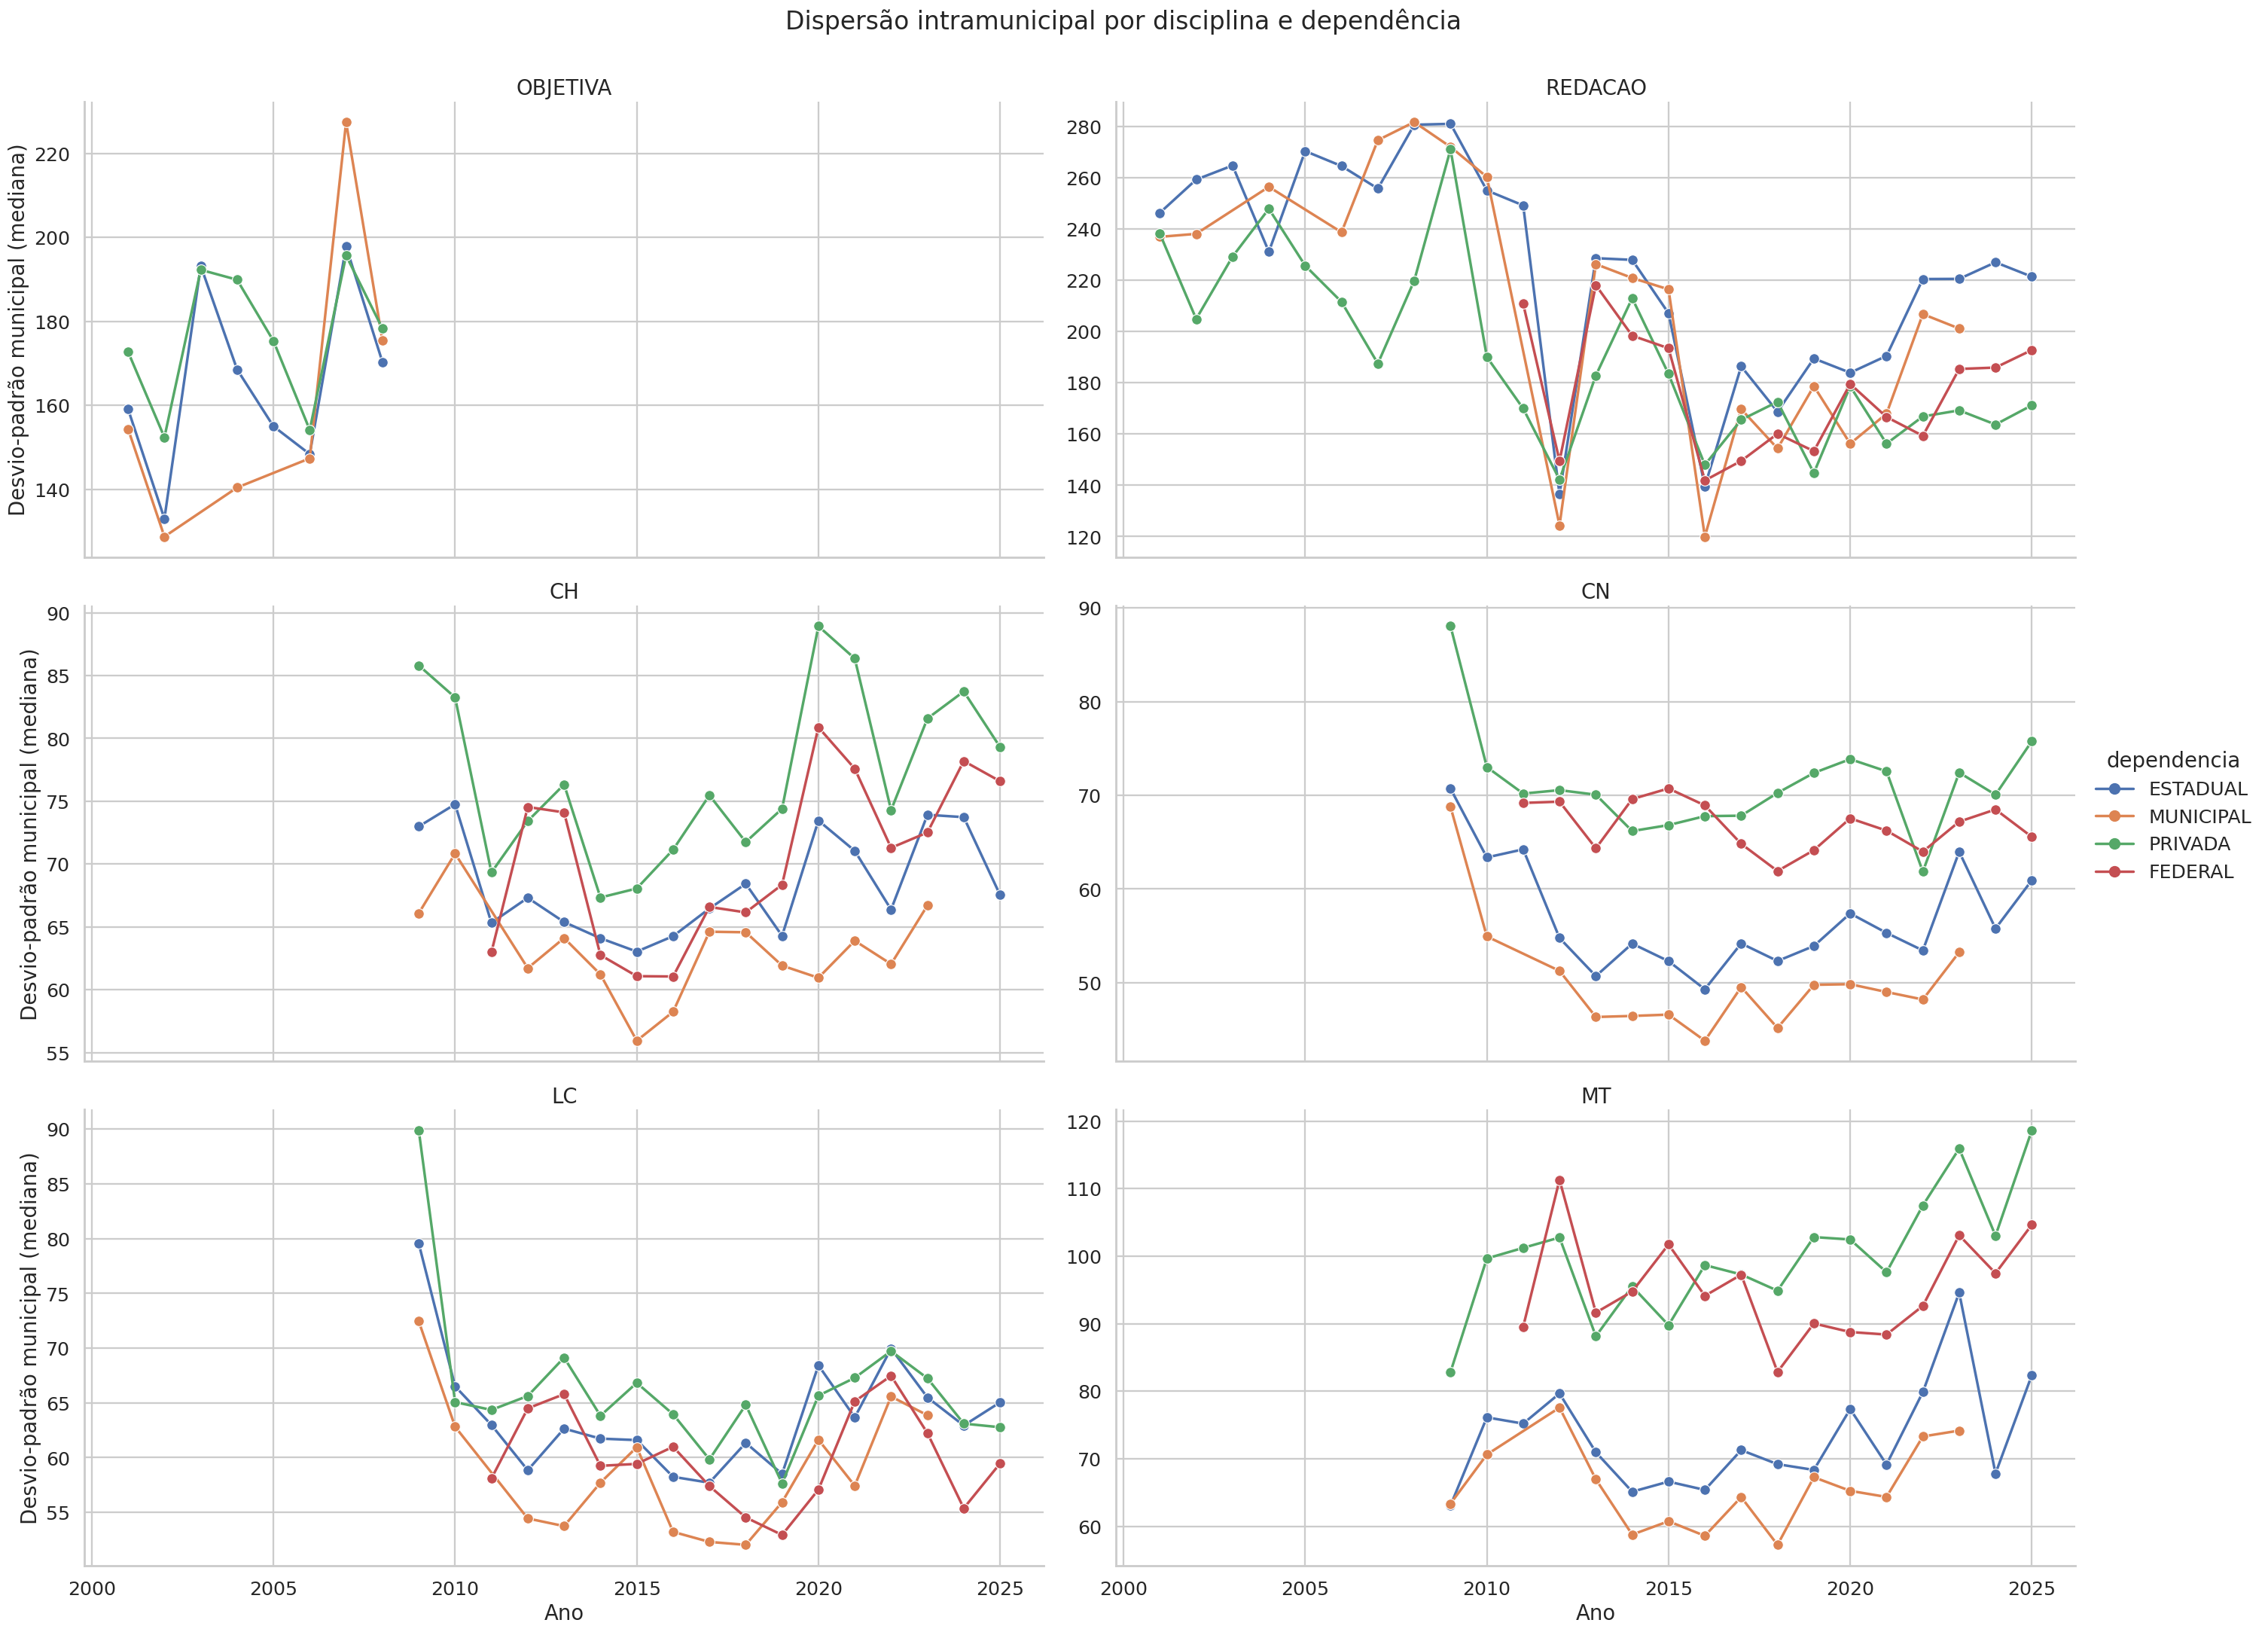

In [8]:
dispersao_municipal = desempenho_dep.copy()
dispersao_municipal["iqr_municipal"] = dispersao_municipal["q3"] - dispersao_municipal["q1"]

dispersao_resumo = dispersao_municipal.groupby(
    ["ano", "disciplina", "dependencia"], as_index=False
).agg(
    std_municipal_mediana=("std", "median"),
    iqr_municipal_mediana=("iqr_municipal", "median"),
    q1_mediana_municipal=("mediana", lambda s: s.quantile(.25)),
    q3_mediana_municipal=("mediana", lambda s: s.quantile(.75)),
    n_municipios=("CO_MUNICIPIO_TERRITORIO", "nunique"),
    n_validos=("n_validos", "sum"),
)
dispersao_resumo["iqr_entre_medianas_municipais"] = (
    dispersao_resumo["q3_mediana_municipal"]
    - dispersao_resumo["q1_mediana_municipal"]
)
#display(dispersao_resumo)
base = dispersao_resumo.query("n_municipios >= 5").copy()

ordem_disc = ["OBJETIVA", "REDACAO", "CH", "CN", "LC", "MT"]

g = sns.relplot(
    data=base, x="ano", y="std_municipal_mediana",
    hue="dependencia", col="disciplina", col_order=ordem_disc,
    col_wrap=2, kind="line", marker="o", height=6.4, aspect=2,
    facet_kws=dict(sharey=False),
)
g.set_titles("{col_name}")
g.set_axis_labels("Ano", "Desvio-padrão municipal (mediana)")
g.figure.suptitle("Dispersão intramunicipal por disciplina e dependência", y=1.03)
plt.show()


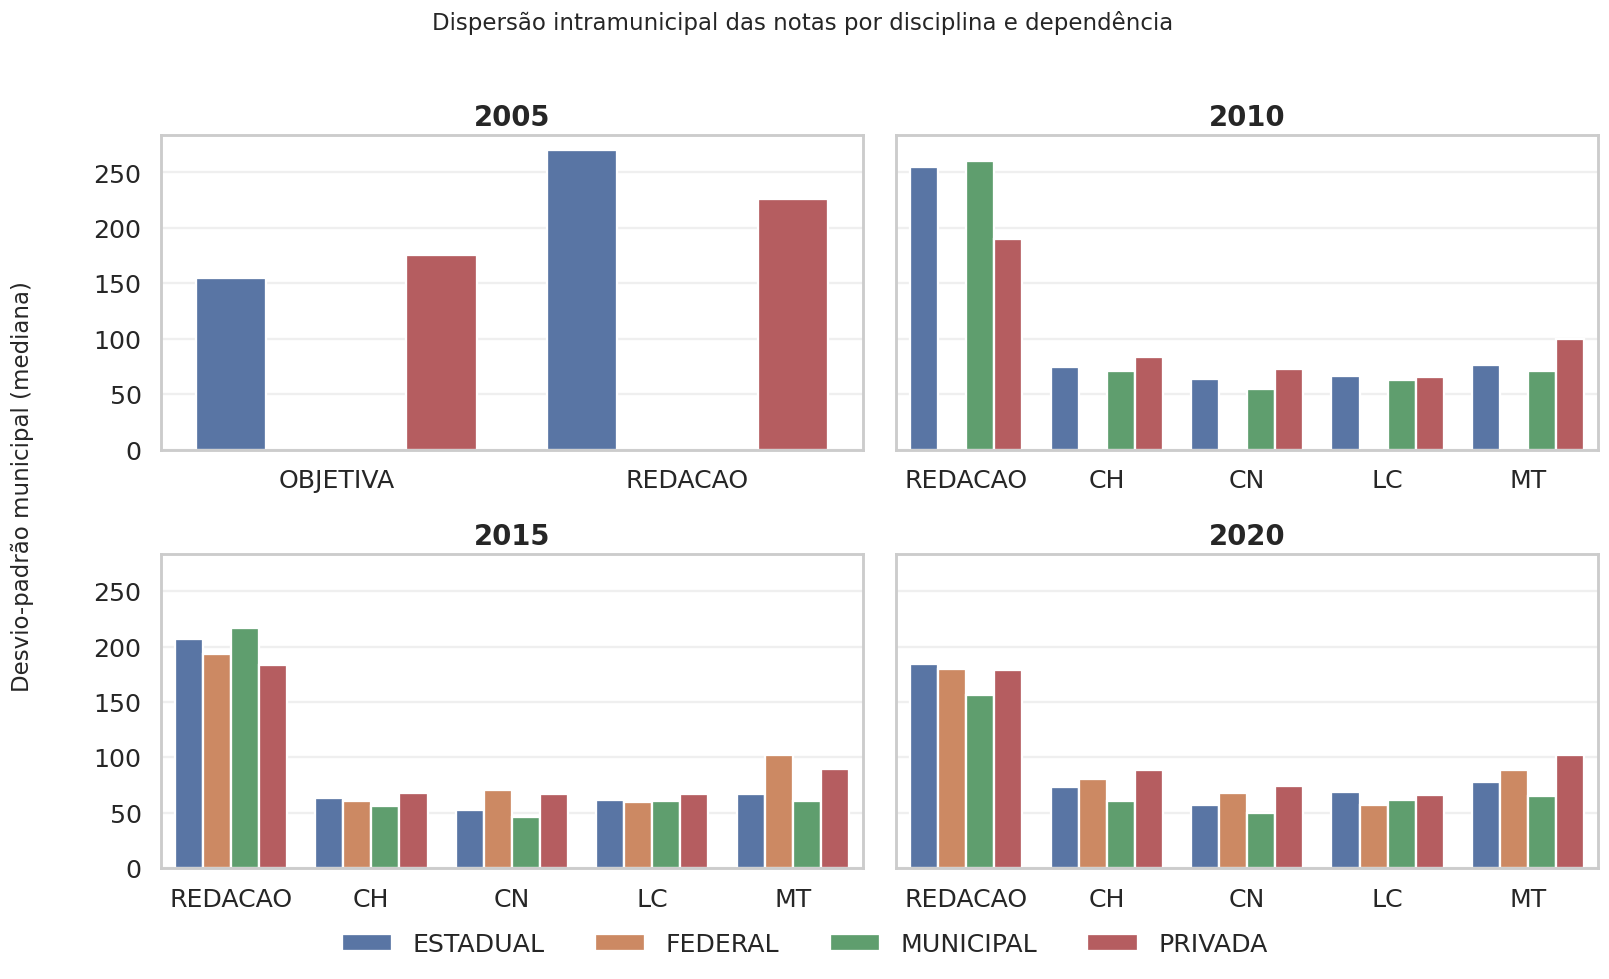

In [9]:
anos = [2005, 2010, 2015, 2020]
ordem_dep = ["ESTADUAL", "FEDERAL", "MUNICIPAL", "PRIVADA"]
paleta = dict(zip(ordem_dep, sns.color_palette("deep", 4)))

d = base[base["ano"].isin(anos)].copy()
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharey=True)
for ax, ano in zip(axes.flat, anos):
    dd = d[d["ano"] == ano]
    ordem_ano = [x for x in ordem_disc if x in dd["disciplina"].unique()]
    sns.barplot(
        data=dd, x="disciplina", y="std_municipal_mediana",
        hue="dependencia", hue_order=ordem_dep, palette=paleta,
        order=ordem_ano, errorbar=None, ax=ax,
    )
    ax.set_title(ano, fontweight="bold")
    ax.set(xlabel="", ylabel="")
    ax.grid(axis="y", alpha=.3); ax.set_axisbelow(True)
    ax.get_legend().remove()

# Um único rótulo Y para a figura toda (substitui os dois set_ylabel)
fig.supylabel("Desvio-padrão municipal (mediana)", fontsize=15)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Dispersão intramunicipal das notas por disciplina e dependência",
             fontsize=15)
plt.tight_layout(rect=[0.02, 0.04, 1, 0.97])
plt.show()

### Comentários

A análise da dispersão considera o comportamento das estatísticas municipais de desvio-padrão e intervalo interquartil.

Os resultados mostram diferenças entre as dependências administrativas e entre as disciplinas. No período de 2009 a 2019, as escolas privadas apresentaram dispersão municipal relativamente elevada em Matemática, com desvio-padrão municipal mediano de aproximadamente 97 pontos e IQR municipal mediano de 128,5 pontos.

No período de 2020 a 2025, esses indicadores aumentaram para aproximadamente 105 e 150 pontos, respectivamente. Nas escolas estaduais, a dispersão também aumentou em Matemática, passando de aproximadamente 69 para 79 pontos no desvio-padrão municipal mediano.Em Ciências da Natureza, por outro lado, a dispersão permaneceu relativamente estável nas escolas municipais e estaduais.
Na Redação, os resultados apresentam comportamento distinto das demais disciplinas. A dispersão municipal é mais elevada, especialmente na rede estadual.

A dispersão das notas não apresenta uma tendência única entre as dependências administrativas. Em algumas disciplinas, observa-se aumento da variabilidade dos resultados municipais; em outras, relativa estabilidade ou redução.

As escolas privadas e federais apresentam dispersão relativamente elevada em algumas disciplinas, especialmente Matemática. Já a rede estadual apresenta dispersão expressiva na Redação. É importante destacar que esses indicadores representam a variabilidade das estatísticas municipais, não a dispersão individual de todos os participantes do estado.

## 8. Síntese dos resultados



Os resultados mostram que a dependência administrativa da escola está associada a diferenças importantes tanto na composição dos participantes quanto no desempenho dos estudantes do ENEM no Pará.

** Participação por dependência administrativa**

A rede pública concentrou historicamente a maior parte dos participantes. Embora a participação das escolas privadas tenha aumentado entre o início dos anos 2000 e 2021, esse crescimento não alterou a predominância do setor público. Nos anos mais recentes, a participação pública voltou a aumentar.

**Diferenças de desempenho entre as redes**

As escolas privadas apresentaram médias superiores às das escolas públicas em todas as disciplinas analisadas. As medianas municipais também indicaram, predominantemente, resultados mais elevados para o setor privado. Essas diferenças foram particularmente expressivas em Matemática e Redação nos anos mais recentes.

A análise das quatro dependências administrativas revelou ainda que as escolas federais apresentaram médias superiores às das escolas privadas entre 2009 e 2019. As escolas estaduais e municipais registraram médias inferiores, com diferenças mais acentuadas em Redação. Embora esses resultados evidenciem desigualdades entre os segmentos da rede de ensino, não permitem atribuí-las exclusivamente à dependência administrativa.

**Relação entre participação e desempenho**

O aumento da participação da rede pública não foi acompanhado por uma trajetória uniforme de melhoria ou redução das médias. A relação entre a proporção de participantes da rede pública e o desempenho variou conforme a disciplina e o período. Portanto, a mudança na composição dos participantes, isoladamente, não explica a evolução dos resultados.

**Desigualdade entre redes nos municípios**

Em 2025, foram identificadas diferenças de desempenho entre escolas públicas e privadas em todas as combinações de município e disciplina que atenderam aos critérios de elegibilidade. Entretanto, a magnitude dessas diferenças variou entre os municípios e as disciplinas.

A comparação histórica apresenta limitações: em uma parcela reduzida das combinações município-disciplina, havia pelo menos 100 notas válidas em cada setor. Essa restrição reduz a cobertura das comparações entre os anos e exige cautela na interpretação da evolução temporal das desigualdades.

**Variabilidade do desempenho**

As diferenças entre as dependências administrativas também aparecem na variabilidade dos resultados municipais, e não apenas nas médias. Esse comportamento varia conforme a rede de ensino e a disciplina, indicando que a desigualdade envolve tanto os níveis médios de desempenho quanto a distribuição dos resultados entre os municípios.

 <div style="background-color: #E2E8F0; padding: 12px; border-radius: 6px;">
    
**Síntese Final**  
Dessa forma, a rede pública concentra a maior parte dos participantes do ENEM no Pará, mas apresenta médias inferiores às da rede privada. Essa desigualdade é persistente, varia entre as áreas do conhecimento e apresenta comportamentos temporais distintos: enquanto as diferenças diminuíram em Ciências Humanas, Ciências da Natureza e Linguagens, aumentaram em Matemática e Redação entre 2009 e 2025. As escolas federais se destacam pelos resultados médios elevados, enquanto as escolas estaduais e municipais apresentam médias inferiores. Os resultados reforçam que as desigualdades educacionais no estado não podem ser compreendidas apenas pela participação no exame: é necessário considerar também a dependência administrativa, a disciplina avaliada, a distribuição territorial e a variabilidade dos resultados
</div>
